# DELE CA1 Part A

WGAN IS NOT FULLY RUN BECAUSE OUT OF TIME


Kazu did initial EDA and preprocessing 

Enzo created the models, DCGAN and WGAN

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import tensorflow as tf
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split

In [26]:
df = pd.read_csv("C:/Users/Enzo/schEnzo/OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")

# Show the first few rows
print(df.head())

# Shape of dataset
print("Shape:", df.shape)  

# Info summary of dataset (columns, non-null counts, datatypes, memory)
print("\n", df.info())

   24    0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.552  0.553  0.554  \
0  -2  142  142  142  142  142  142  142  142  142  ...    142    142    142   
1  15    0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  14    0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  -2  120  120  120  120  120  120  120  120  120  ...    120    120    120   
4  -1  131  131  131  131  131  131  131  131  200  ...    131    131    131   

   0.555  0.556  0.557  0.558  0.559  0.560  0.561  
0    142    142    142    142    142    142    142  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3    120    120    120    120    120    120    120  
4    131    131    131    131    131    131    131  

[5 rows x 785 columns]
Shape: (64828, 785)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64828 entries, 0 to 64827
Columns: 785 entries, 24 to 0.561
dtypes: int64(785)
memory usage: 388.3 MB

 Non

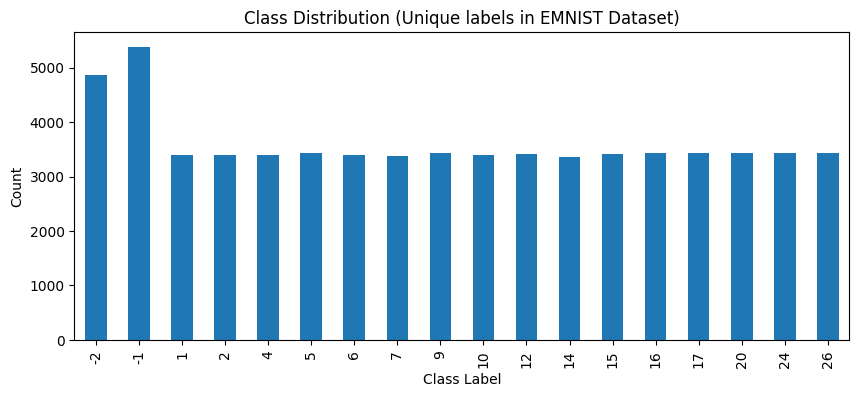

Unique labels in dataset: [-2, -1, 1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]


In [27]:
labels = df.iloc[:, 0]  # First column is label (1 to 26 for A-Z)

plt.figure(figsize=(10, 4))
labels.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution (Unique labels in EMNIST Dataset)")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

print("Unique labels in dataset:", sorted(df.iloc[:, 0].unique()))

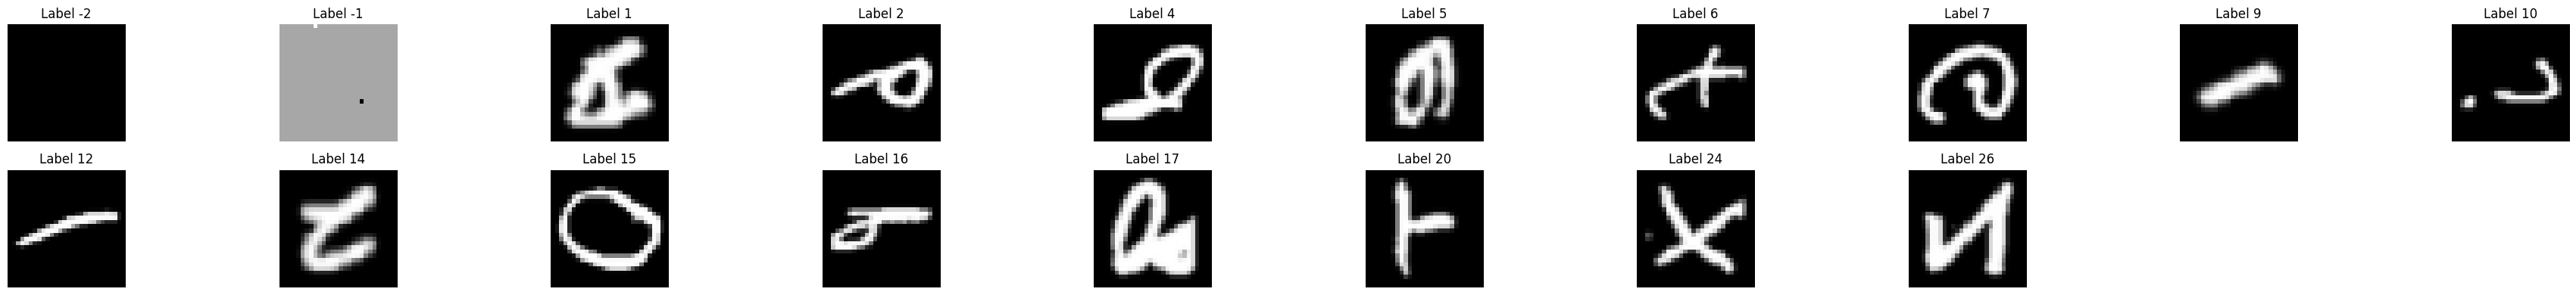

In [28]:
available_labels = sorted(df.iloc[:, 0].unique())

plt.figure(figsize=(len(available_labels) * 2, 4))  # Adjust figure width dynamically
for i, label in enumerate(available_labels):
    img = df[df.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    plt.subplot(2, len(available_labels) // 2 + 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

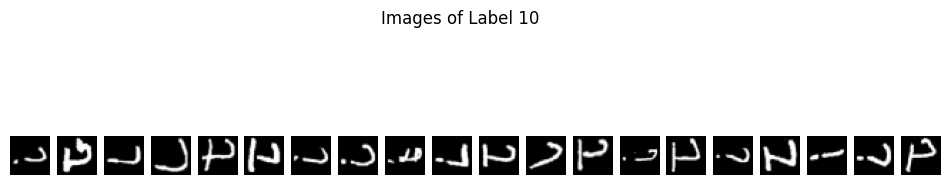

In [29]:
label_to_show = 10

subset = df[df.iloc[:, 0] == label_to_show]

plt.figure(figsize=(12, 3))
for i in range(20):
    img = subset.iloc[i, 1:].values.reshape(28, 28)
    plt.subplot(1, 20, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle(f"Images of Label {label_to_show}")
plt.show()

# -2 -1 9 10 12 are weird, -2 -1 not real, -10 ?????, 9 12 look same

DROPPED -2 AND -1

In [30]:
# Your original labels
labels = df.iloc[:, 0].values

# Filter out invalid labels, e.g. negative values
valid_labels_mask = labels >= 0
labels = labels[valid_labels_mask]

# Extract and reshape image pixels
X_filtered = df.iloc[valid_labels_mask, 1:].values.astype('float32')  # before reshape, for stats

# Compute mean and std before normalization
pixel_mean_raw = X_filtered.mean()
pixel_std_raw = X_filtered.std()
print("Raw pixel mean:", pixel_mean_raw)
print("Raw pixel std:", pixel_std_raw)

Raw pixel mean: 43.943172
Raw pixel std: 84.49391


In [31]:
# Normalize to [-1, 1] for GANs
X_filtered = (X_filtered - 127.5) / 127.5

X_filtered = X_filtered.reshape(-1, 28, 28, 1)

# Sanity checke)
print("Pixel mean:", X_filtered.mean())
print("Pixel std:", X_filtered.std())

Pixel mean: -0.65534747
Pixel std: 0.6626988


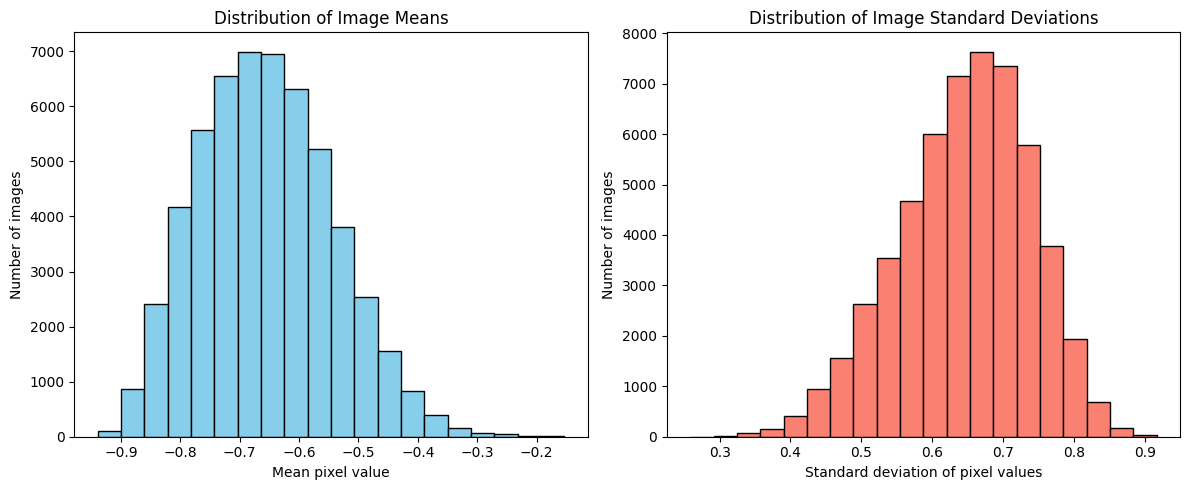

In [32]:
image_means = X_filtered.reshape(X_filtered.shape[0], -1).mean(axis=1)
image_stds = X_filtered.reshape(X_filtered.shape[0], -1).std(axis=1)
plt.figure(figsize=(12, 5))

# Histogram of image means
plt.subplot(1, 2, 1)
plt.hist(image_means, bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Image Means')
plt.xlabel('Mean pixel value')
plt.ylabel('Number of images')

# Histogram of image std deviations
plt.subplot(1, 2, 2)
plt.hist(image_stds, bins=20, color='salmon', edgecolor='black')
plt.title('Distribution of Image Standard Deviations')
plt.xlabel('Standard deviation of pixel values')
plt.ylabel('Number of images')

plt.tight_layout()
plt.show()

In [33]:
# Get unique sorted valid labels
unique_labels = sorted(np.unique(labels))

# Map original labels to zero-based
label_to_index = {label: idx for idx, label in enumerate(unique_labels)}
mapped_labels = np.array([label_to_index[label] for label in labels])

# Check mapping
print("Original labels:", unique_labels)
print("Mapped label range:", mapped_labels.min(), "to", mapped_labels.max())

Original labels: [1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]
Mapped label range: 0 to 15


In [34]:
BUFFER_SIZE = 10000
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(X_filtered) \
    .shuffle(BUFFER_SIZE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# # Split before creating tf.data.Dataset 
# X_train, X_val, y_train, y_val = train_test_split(
#     X_filtered, mapped_labels, test_size=0.2, random_state=42, stratify=mapped_labels
# )

# # Create tf.data.Dataset objects
# train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
# val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
# NOT SURE IF SHOULD SPLIT DATAAAAAA 

In [ ]:
# === 2. Generator Model ===
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)),  # 7x7x512

        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

# === 3. Discriminator Model ===
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

# === 4. Loss & Optimizer ===
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator = make_generator_model()
discriminator = make_discriminator_model()

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

Epoch 1/20


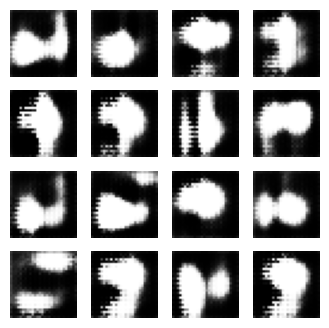

Epoch 2/20


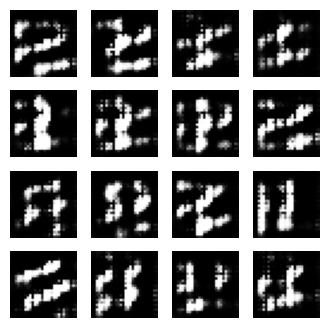

Epoch 3/20


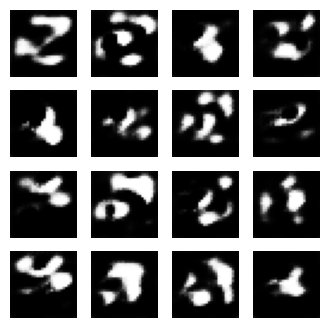

Epoch 4/20


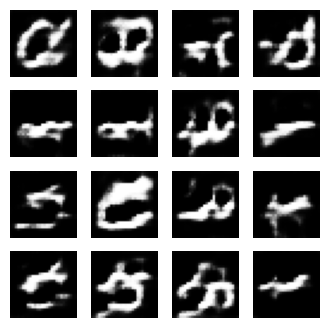

Epoch 5/20


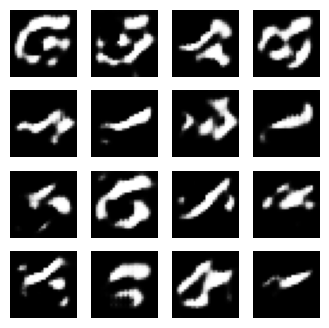

Epoch 6/20


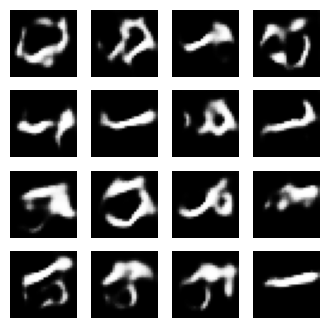

Epoch 7/20


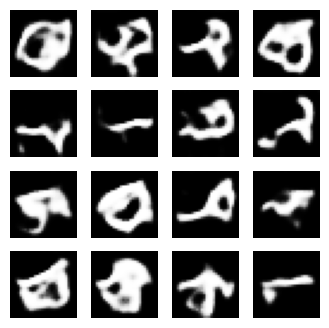

Epoch 8/20


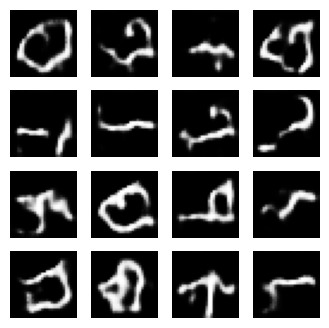

Epoch 9/20


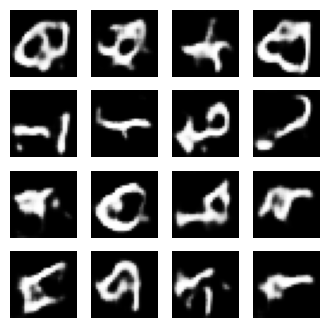

Epoch 10/20


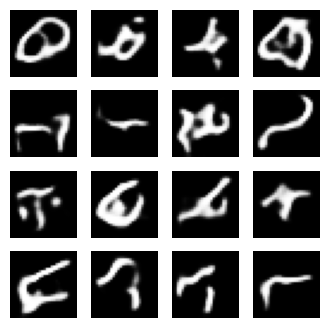

Epoch 11/20


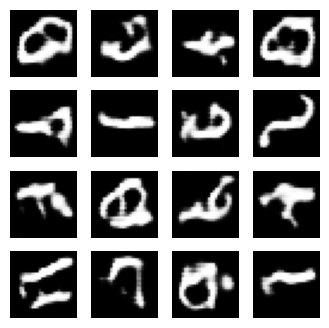

Epoch 12/20


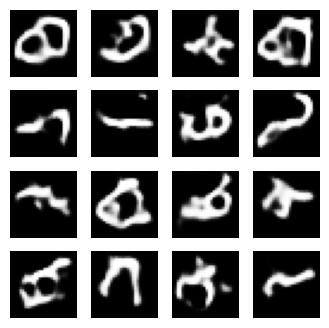

Epoch 13/20


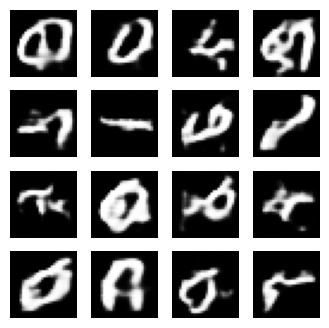

Epoch 14/20


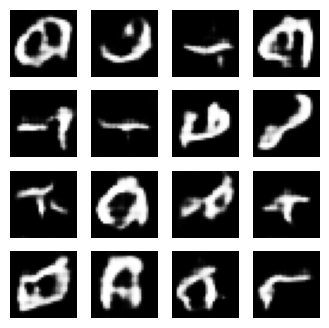

Epoch 15/20


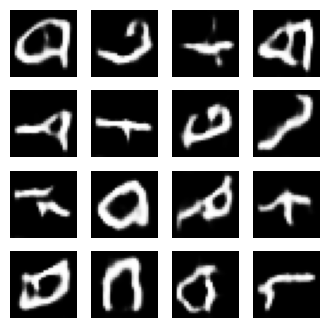

Epoch 16/20


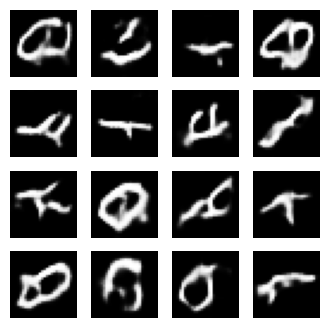

Epoch 17/20


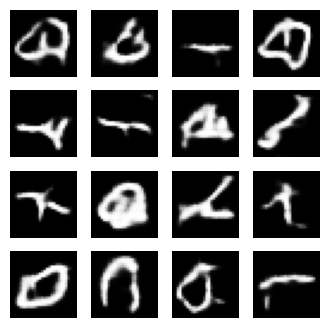

Epoch 18/20


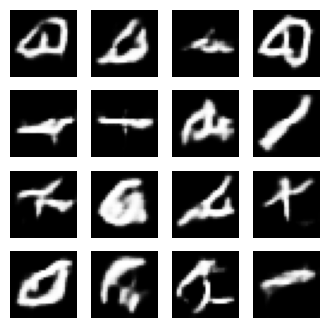

Epoch 19/20


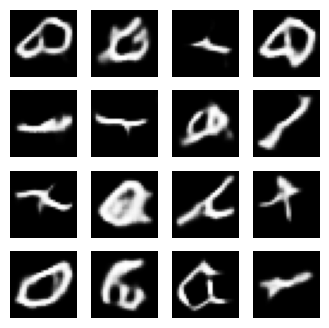

Epoch 20/20


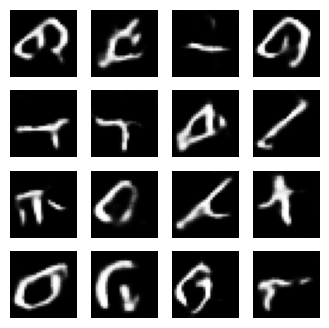

In [36]:
# === 5. Training Loop ===
EPOCHS = 20
noise_dim = 256
num_examples_to_generate = 16
seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    predictions = (predictions + 1) / 2.0  # Rescale to [0, 1]

    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(predictions[i, :, :, 0], cmap='gray')
        plt.axis('off')
    plt.savefig(f'image_epoch_{epoch}.png')
    plt.show()

def train(dataset, epochs):
    for epoch in range(epochs):
        print(f"Epoch {epoch+1}/{epochs}")
        for image_batch in dataset:
            train_step(image_batch)
        generate_and_save_images(generator, epoch + 1, seed)

train(train_dataset, EPOCHS)

Epoch 1/20
Generator loss: -13.7686, Critic loss: -2.4370


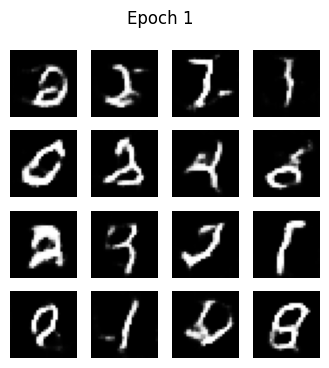

Epoch 2/20
Generator loss: -8.8994, Critic loss: -1.1047


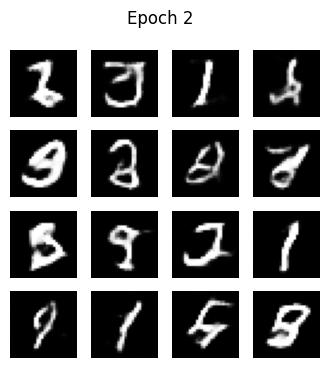

Epoch 3/20
Generator loss: -10.1118, Critic loss: -1.7760


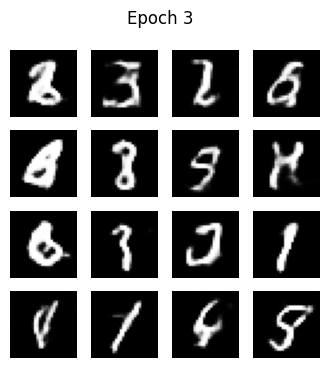

Epoch 4/20
Generator loss: -12.3205, Critic loss: -1.2329


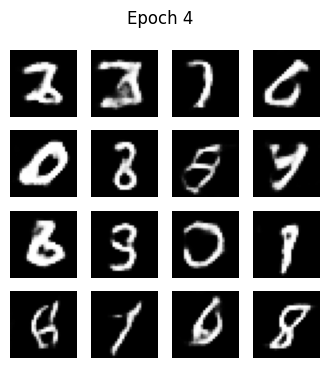

Epoch 5/20
Generator loss: -7.9863, Critic loss: -1.4275


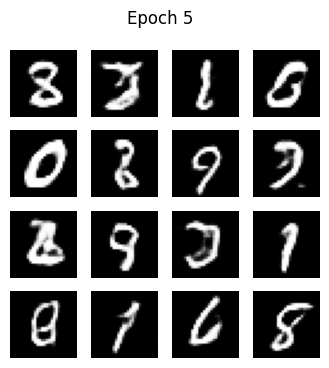

Epoch 6/20
Generator loss: -9.5811, Critic loss: -0.7326


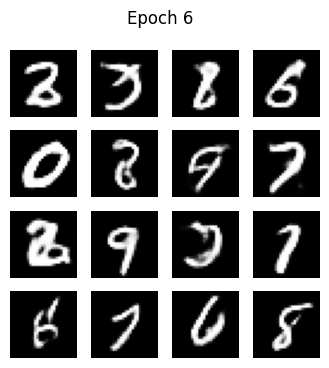

Epoch 7/20
Generator loss: -10.6147, Critic loss: -2.0907


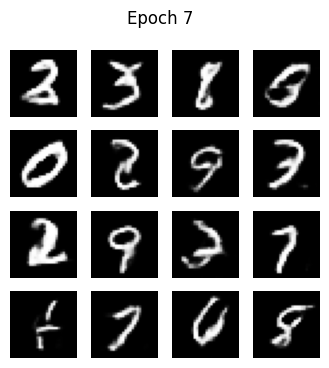

Epoch 8/20
Generator loss: -8.5951, Critic loss: -1.5152


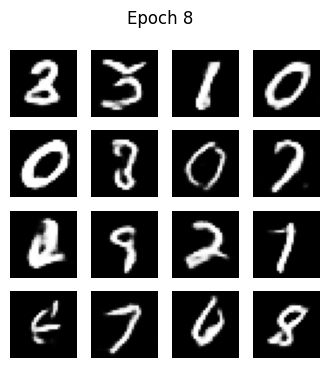

Epoch 9/20
Generator loss: -10.6161, Critic loss: -1.5098


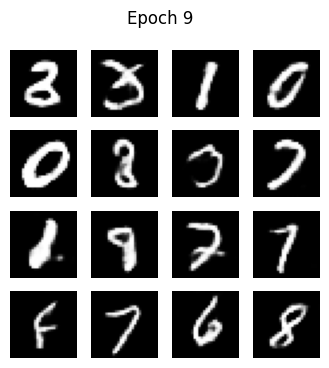

Epoch 10/20
Generator loss: -11.4429, Critic loss: -1.2816


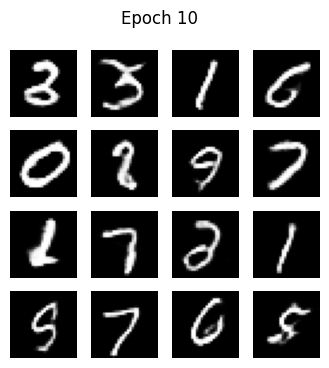

Epoch 11/20
Generator loss: -4.2876, Critic loss: -0.6031


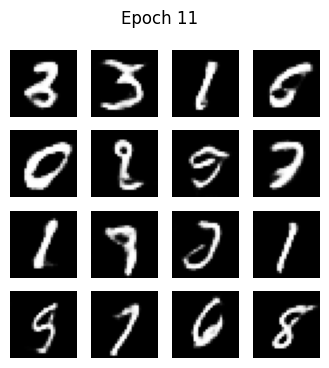

Epoch 12/20
Generator loss: -3.6705, Critic loss: -0.2474


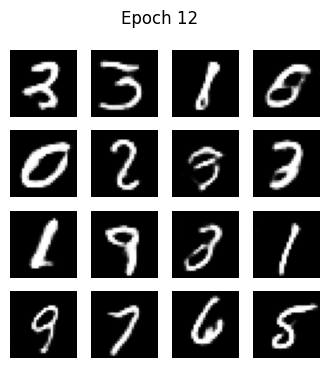

Epoch 13/20
Generator loss: -7.0295, Critic loss: -0.5075


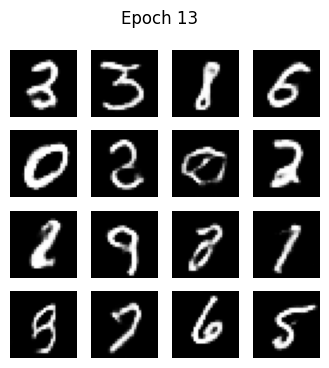

Epoch 14/20
Generator loss: -5.1754, Critic loss: -0.6666


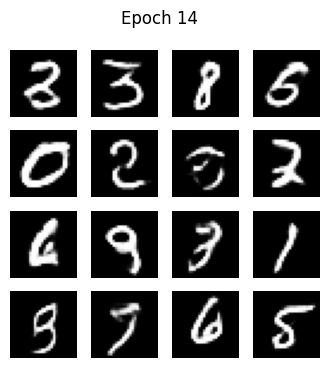

Epoch 15/20
Generator loss: -1.1189, Critic loss: -1.5432


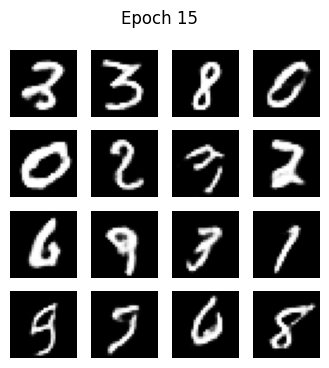

Epoch 16/20
Generator loss: -5.0133, Critic loss: -1.8597


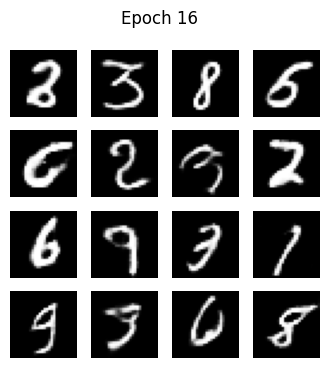

Epoch 17/20
Generator loss: -1.4475, Critic loss: -0.8801


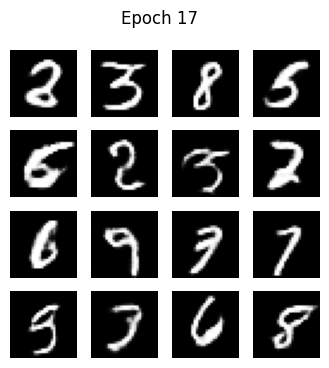

Epoch 18/20
Generator loss: 0.2644, Critic loss: -0.9079


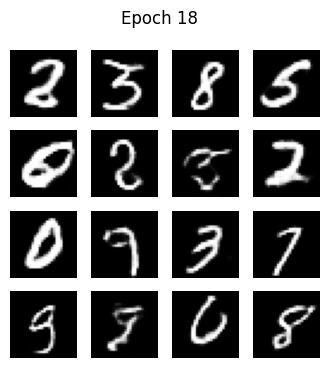

Epoch 19/20
Generator loss: 3.2062, Critic loss: -0.7200


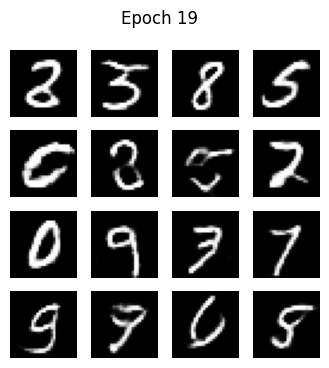

Epoch 20/20
Generator loss: 2.8128, Critic loss: -0.5599


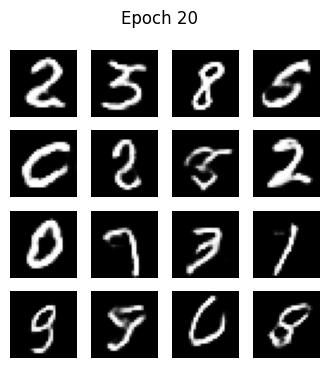

In [40]:
# === Generator Model ===
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)),

        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

# === Discriminator (Critic) Model ===
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)  # No activation for WGAN
    ])
    return model

# === Gradient Penalty ===
def gradient_penalty(discriminator, real_images, fake_images):
    batch_size = real_images.shape[0]
    alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
    interpolated = real_images + alpha * (fake_images - real_images)
    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        pred = discriminator(interpolated, training=True)
    grads = tape.gradient(pred, [interpolated])[0]
    grads = tf.reshape(grads, [batch_size, -1])
    grads_norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=1) + 1e-12)
    gp = tf.reduce_mean((grads_norm - 1.0) ** 2)
    return gp

# === Loss functions ===
def discriminator_loss(real_output, fake_output, gp, lambda_gp=10.0):
    return tf.reduce_mean(fake_output) - tf.reduce_mean(real_output) + lambda_gp * gp

def generator_loss(fake_output):
    return -tf.reduce_mean(fake_output)

# === Hyperparameters ===
EPOCHS = 20
noise_dim = 256
BATCH_SIZE = 64
CRITIC_ITERATIONS = 5
LAMBDA_GP = 10.0

# === Optimizers for WGAN-GP ===
generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)

# === Create models ===
generator = make_generator_model()
discriminator = make_discriminator_model()

# === Seed for generating images ===
num_examples_to_generate = 16
seed = tf.random.normal([num_examples_to_generate, noise_dim])

# === Training Step ===
@tf.function
def train_step(real_images):
    batch_size = real_images.shape[0]
    for _ in range(CRITIC_ITERATIONS):
        noise = tf.random.normal([batch_size, noise_dim])
        with tf.GradientTape() as disc_tape:
            fake_images = generator(noise, training=True)
            real_output = discriminator(real_images, training=True)
            fake_output = discriminator(fake_images, training=True)
            gp = gradient_penalty(discriminator, real_images, fake_images)
            disc_loss = discriminator_loss(real_output, fake_output, gp, LAMBDA_GP)
        gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
        discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    noise = tf.random.normal([batch_size, noise_dim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))

    return gen_loss, disc_loss

# === Generate and save images ===
def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    predictions = (predictions + 1) / 2.0  # Rescale [-1,1] to [0,1]

    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(predictions[i, :, :, 0], cmap='gray')
        plt.axis('off')
    plt.suptitle(f'Epoch {epoch}')
    plt.show()

# === Preprocess function ===
def preprocess(image):
    image = tf.cast(image, tf.float32)
    image = (image - 127.5) / 127.5  # Normalize to [-1, 1]
    image = tf.expand_dims(image, axis=-1)  # Add channel dimension for grayscale
    return image

# === Load and prepare dataset ===
(train_images, _), (_, _) = tf.keras.datasets.mnist.load_data()
train_images = train_images.astype('float32')
train_dataset = tf.data.Dataset.from_tensor_slices(train_images)
train_dataset = train_dataset.map(preprocess).shuffle(60000).batch(BATCH_SIZE)

# === Training loop ===
def train(dataset, epochs):
    for epoch in range(epochs):
        print(f"Epoch {epoch + 1}/{epochs}")
        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)
        print(f"Generator loss: {gen_loss:.4f}, Critic loss: {disc_loss:.4f}")
        generate_and_save_images(generator, epoch + 1, seed)

# === Start training ===
train(train_dataset, EPOCHS)

In [37]:
# # === Generator for cGAN ===
# def make_generator_model():
#     noise_input = layers.Input(shape=(100,))
#     label_input = layers.Input(shape=(1,), dtype='int32')

#     label_embedding = layers.Embedding(num_classes, 100)(label_input)
#     label_embedding = layers.Flatten()(label_embedding)

#     model_input = layers.Multiply()([noise_input, label_embedding])

#     x = layers.Dense(7*7*256, use_bias=False)(model_input)
#     x = layers.BatchNormalization()(x)
#     x = layers.LeakyReLU()(x)

#     x = layers.Reshape((7, 7, 256))(x)

#     x = layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False)(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.LeakyReLU()(x)

#     x = layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False)(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.LeakyReLU()(x)

#     out = layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')(x)

#     return tf.keras.Model([noise_input, label_input], out)

# # === Discriminator for cGAN ===
# def make_discriminator_model():
#     img_input = layers.Input(shape=(28, 28, 1))
#     label_input = layers.Input(shape=(1,), dtype='int32')

#     label_embedding = layers.Embedding(num_classes, 28*28)(label_input)
#     label_embedding = layers.Reshape((28, 28, 1))(label_embedding)

#     x = layers.Concatenate(axis=-1)([img_input, label_embedding])

#     x = layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same')(x)
#     x = layers.LeakyReLU()(x)
#     x = layers.Dropout(0.3)(x)

#     x = layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same')(x)
#     x = layers.LeakyReLU()(x)
#     x = layers.Dropout(0.3)(x)

#     x = layers.Flatten()(x)
#     out = layers.Dense(1)(x)

#     return tf.keras.Model([img_input, label_input], out)

# # === Loss & optimizers ===
# cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# def discriminator_loss(real_output, fake_output):
#     real_loss = cross_entropy(tf.ones_like(real_output), real_output)
#     fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
#     return real_loss + fake_loss

# def generator_loss(fake_output):
#     return cross_entropy(tf.ones_like(fake_output), fake_output)

# generator = make_generator_model()
# discriminator = make_discriminator_model()

# generator_optimizer = tf.keras.optimizers.Adam(1e-4)
# discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

# # === Training Setup ===
# EPOCHS = 10
# noise_dim = 100
# num_examples_to_generate = 16

# seed_noise = tf.random.normal([num_examples_to_generate, noise_dim])
# seed_labels = tf.constant([i for i in range(num_examples_to_generate)])  # Labels 0 to 15

# @tf.function
# def train_step(images, labels):
#     noise = tf.random.normal([BATCH_SIZE, noise_dim])
#     random_labels = tf.random.uniform([BATCH_SIZE, 1], minval=0, maxval=num_classes, dtype=tf.int32)

#     with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
#         generated_images = generator([noise, random_labels], training=True)

#         real_output = discriminator([images, tf.expand_dims(labels, 1)], training=True)
#         fake_output = discriminator([generated_images, random_labels], training=True)

#         gen_loss = generator_loss(fake_output)
#         disc_loss = discriminator_loss(real_output, fake_output)

#     gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
#     gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

#     generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
#     discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

# def generate_and_show_images(model, epoch, test_noise, test_labels):
#     predictions = model([test_noise, test_labels], training=False)
#     predictions = (predictions + 1) / 2.0  # Scale to [0,1]

#     fig = plt.figure(figsize=(4,4))
#     for i in range(predictions.shape[0]):
#         plt.subplot(4,4,i+1)
#         plt.imshow(predictions[i,:,:,0], cmap='gray')
#         plt.axis('off')
#     plt.suptitle(f"Epoch {epoch}")
#     plt.show()

# def train(dataset, epochs):
#     for epoch in range(epochs):
#         print(f"Epoch {epoch+1}/{epochs}")
#         for image_batch, label_batch in dataset:
#             train_step(image_batch, label_batch)
#         generate_and_show_images(generator, epoch+1, seed_noise, seed_labels)

# # === Start training ===
# train(dataset_images_and_labels, EPOCHS)